<a href="https://colab.research.google.com/github/miso88oup/image-caption-generator/blob/main/notebooks/03_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Caption Generator — Training

CNN–LSTM decoder trained separately on features from each encoder (VGG16, ResNet50, InceptionV3), using identical hyperparameters.

The image feature vector initialises the LSTM's hidden and cell states. The LSTM then predicts each next word from the words before it (teacher forcing).

## 1. Setup

In [1]:
import os
import json
import pickle

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/image-caption-project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
FEATURES_DIR = os.path.join(PROJECT_DIR, 'features')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
with open(os.path.join(DATA_DIR, 'captions_clean.json')) as f:
    captions = json.load(f)
with open(os.path.join(DATA_DIR, 'splits.json')) as f:
    splits = json.load(f)
with open(os.path.join(DATA_DIR, 'vocab.json')) as f:
    vocab = json.load(f)

word2idx = vocab['word2idx']
vocab_size = vocab['vocab_size']
max_length = vocab['max_length']

print('Vocabulary size:', vocab_size)
print('Max caption length:', max_length)

Vocabulary size: 2559
Max caption length: 38


## 2. Hyperparameters

In [3]:
EMBED_DIM = 256
UNITS = 512
DROPOUT = 0.5
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
EPOCHS = 20
PATIENCE = 3
SEED = 42

ENCODERS = ['vgg16', 'resnet50', 'inceptionv3']

## 3. Training Data

Each caption is padded to `max_length`. Input = caption without the last word, target = caption shifted by one word. Padding positions get zero weight in the loss.

In [4]:
def encode(caption):
    return [word2idx.get(w, 1) for w in caption.split()]


def build_sequences(image_names):
    image_ids, seqs = [], []
    for i, img in enumerate(image_names):
        for cap in captions[img]:
            image_ids.append(i)
            seqs.append(encode(cap))
    seqs = keras.utils.pad_sequences(seqs, maxlen=max_length, padding='post')
    x = seqs[:, :-1]
    y = seqs[:, 1:]
    w = (y != 0).astype('float32')
    return np.array(image_ids), x, y, w


def make_dataset(features, image_names, shuffle):
    feat_matrix = tf.constant(np.stack([features[img] for img in image_names]), dtype=tf.float32)
    image_ids, x, y, w = build_sequences(image_names)

    ds = tf.data.Dataset.from_tensor_slices((image_ids, x, y, w))
    if shuffle:
        ds = ds.shuffle(len(x), seed=SEED)
    ds = ds.map(lambda i, x, y, w: ((tf.gather(feat_matrix, i), x), y, w))
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


image_ids, x, y, w = build_sequences(splits['train'][:1])
print('Input :', x[0][:12])
print('Target:', y[0][:12])

Input : [2117    2  221   45 2510  625 1119 1621 2525    2 1901 1090]
Target: [   2  221   45 2510  625 1119 1621 2525    2 1901 1090    2]


## 4. Model

In [5]:
def build_model(feature_dim):
    image_input = keras.Input(shape=(feature_dim,), name='image_features')
    caption_input = keras.Input(shape=(None,), dtype='int32', name='caption')

    img = layers.BatchNormalization()(image_input)
    img = layers.Dropout(DROPOUT)(img)
    h0 = layers.Dense(UNITS, activation='tanh', name='init_h')(img)
    c0 = layers.Dense(UNITS, activation='tanh', name='init_c')(img)

    emb = layers.Embedding(vocab_size, EMBED_DIM, mask_zero=True, name='embedding')(caption_input)
    emb = layers.Dropout(DROPOUT)(emb)
    seq = layers.LSTM(UNITS, return_sequences=True, name='lstm')(emb, initial_state=[h0, c0])
    seq = layers.Dropout(DROPOUT)(seq)
    output = layers.Dense(vocab_size, activation='softmax', name='next_word')(seq)

    model = keras.Model([image_input, caption_input], output)
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        weighted_metrics=['accuracy'],
    )
    return model


build_model(2048).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2048)      │      8,192 │ image_features[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 256) │    655,104 │ caption[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, None, 256) │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ init_h (Dense)      │ (None, 512)       │  1,049,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ init_c (Dense)      │ (None, 512)       │  1,049,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, None, 512) │  1,574,912 │ dropout_1[0][0],  │
│                     │                   │            │ init_h[0][0],     │
│                     │                   │            │ init_c[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, None, 512) │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, None,      │  1,312,767 │ dropout_2[0][0]   │
│                     │ 2559)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,649,151 (21.55 MB)

 Trainable params: 5,645,055 (21.53 MB)

 Non-trainable params: 4,096 (16.00 KB)

## 5. Train

Each encoder is trained with the same settings. Early stopping keeps the weights with the lowest validation loss. Encoders that are already trained are skipped.

In [6]:
histories = {}

for name in ENCODERS:
    model_path = os.path.join(MODELS_DIR, f'{name}.keras')
    history_path = os.path.join(RESULTS_DIR, f'history_{name}.json')
    if os.path.exists(model_path) and os.path.exists(history_path):
        print(f'{name}: already trained')
        with open(history_path) as f:
            histories[name] = json.load(f)
        continue

    keras.utils.set_random_seed(SEED)

    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features = pickle.load(f)
    feature_dim = len(next(iter(features.values())))

    train_ds = make_dataset(features, splits['train'], shuffle=True)
    val_ds = make_dataset(features, splits['val'], shuffle=False)

    model = build_model(feature_dim)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True),
    ]

    print(f'\nTraining {name} (feature size {feature_dim})')
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)

    histories[name] = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    with open(history_path, 'w') as f:
        json.dump(histories[name], f)

    del model, features
    keras.backend.clear_session()


Training vgg16 (feature size 4096)
Epoch 1/20
469/469 - 24s - 51ms/step - accuracy: 0.2389 - loss: 4.1676 - val_accuracy: 0.3057 - val_loss: 3.4031
Epoch 2/20
469/469 - 36s - 78ms/step - accuracy: 0.3239 - loss: 3.2582 - val_accuracy: 0.3379 - val_loss: 3.0720
Epoch 3/20
469/469 - 18s - 39ms/step - accuracy: 0.3471 - loss: 3.0029 - val_accuracy: 0.3524 - val_loss: 2.9178
Epoch 4/20
469/469 - 21s - 44ms/step - accuracy: 0.3630 - loss: 2.8463 - val_accuracy: 0.3634 - val_loss: 2.8235
Epoch 5/20
469/469 - 19s - 40ms/step - accuracy: 0.3761 - loss: 2.7284 - val_accuracy: 0.3690 - val_loss: 2.7660
Epoch 6/20
469/469 - 20s - 44ms/step - accuracy: 0.3873 - loss: 2.6372 - val_accuracy: 0.3754 - val_loss: 2.7172
Epoch 7/20
469/469 - 18s - 39ms/step - accuracy: 0.3963 - loss: 2.5585 - val_accuracy: 0.3807 - val_loss: 2.6832
Epoch 8/20
469/469 - 20s - 42ms/step - accuracy: 0.4040 - loss: 2.4935 - val_accuracy: 0.3829 - val_loss: 2.6636
Epoch 9/20
469/469 - 19s - 41ms/step - accuracy: 0.4118 - lo

## 6. Training Curves

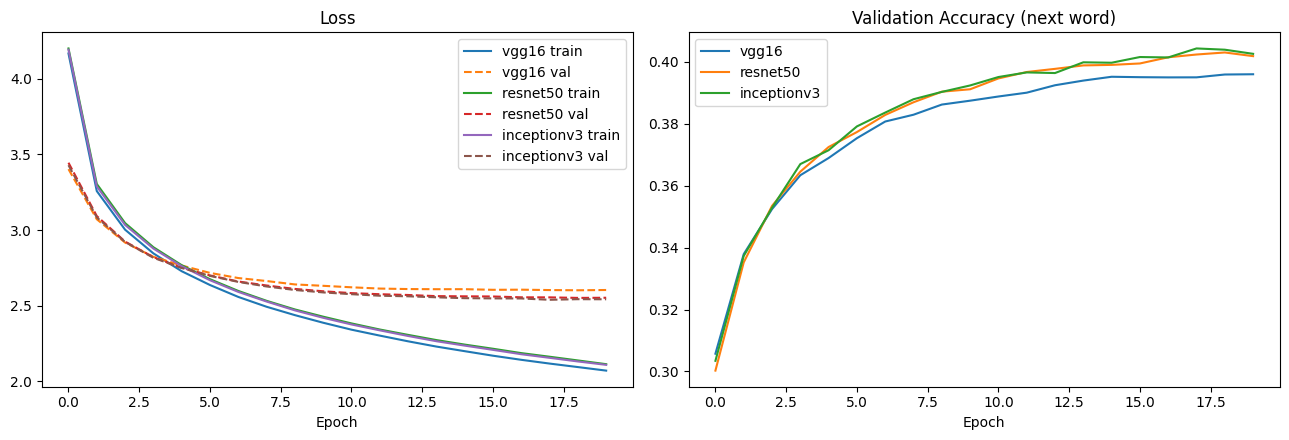

vgg16        best epoch 19 | val loss 2.602 | val acc 0.396
resnet50     best epoch 19 | val loss 2.552 | val acc 0.403
inceptionv3  best epoch 18 | val loss 2.540 | val acc 0.404


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name in ENCODERS:
    h = histories[name]
    axes[0].plot(h['loss'], label=f'{name} train')
    axes[0].plot(h['val_loss'], '--', label=f'{name} val')
    axes[1].plot(h['val_accuracy'], label=name)

axes[0].set_title('Loss')
axes[1].set_title('Validation Accuracy (next word)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

for name in ENCODERS:
    h = histories[name]
    best = int(np.argmin(h['val_loss']))
    print(f'{name:12s} best epoch {best + 1:2d} | val loss {h["val_loss"][best]:.3f} | val acc {h["val_accuracy"][best]:.3f}')

## 7. Sample Captions (greedy)

In [8]:
idx2word = {i: w for w, i in word2idx.items()}


def greedy_caption(model, feature):
    seq = [word2idx['startseq']]
    for _ in range(max_length):
        probs = model.predict([feature[None, :], np.array([seq])], verbose=0)[0, -1]
        next_id = int(np.argmax(probs))
        if idx2word[next_id] == 'endseq':
            break
        seq.append(next_id)
    return ' '.join(idx2word[i] for i in seq[1:])


test_samples = splits['test'][:3]

for name in ENCODERS:
    model = keras.models.load_model(os.path.join(MODELS_DIR, f'{name}.keras'))
    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features = pickle.load(f)
    print(f'\n{name}')
    for img in test_samples:
        print(f'  {img}: {greedy_caption(model, features[img])}')
    del model, features
    keras.backend.clear_session()


vgg16
  2509824208_247aca3ea3.jpg: a brown dog running in the grass
  3613424631_3ae537624f.jpg: a group of people are sitting on a dirt wall
  2774362575_7543b8bf19.jpg: a black dog is playing with a ball in the snow

resnet50
  2509824208_247aca3ea3.jpg: a dog running in the grass
  3613424631_3ae537624f.jpg: a man in a blue shirt is doing a trick on a ramp
  2774362575_7543b8bf19.jpg: a black dog and a black dog are playing in the water

inceptionv3
  2509824208_247aca3ea3.jpg: a brown dog is running through a grassy field
  3613424631_3ae537624f.jpg: a man on a bike is jumping over a ramp
  2774362575_7543b8bf19.jpg: a black dog and a black dog are playing with a toy


Using Colab cache for faster access to the 'flickr8k' dataset.


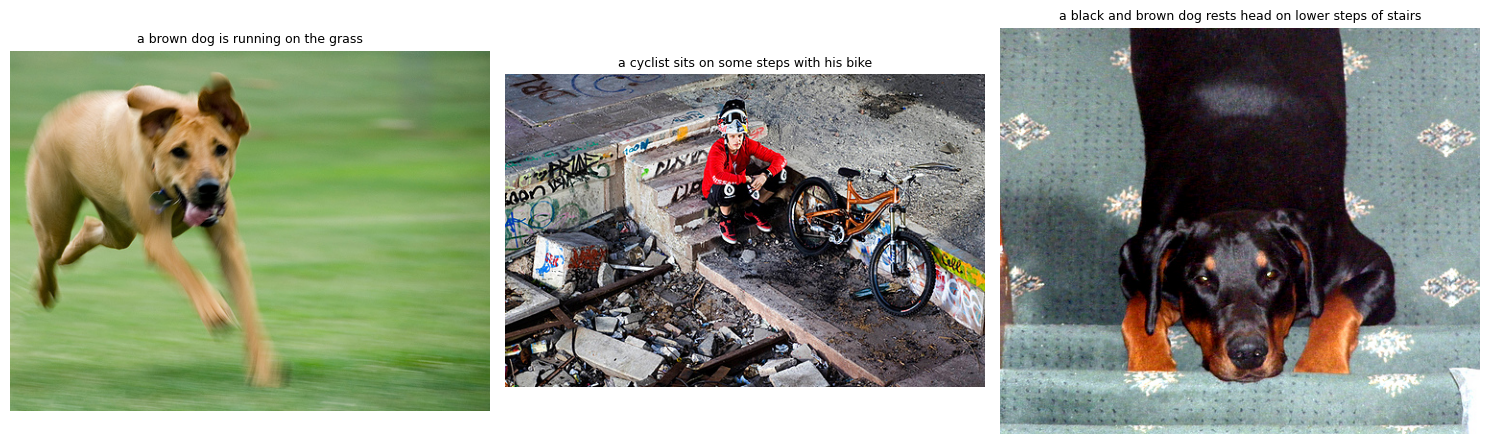

In [9]:
import kagglehub
from PIL import Image

IMAGE_DIR = os.path.join(kagglehub.dataset_download('adityajn105/flickr8k'), 'Images')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img in zip(axes, test_samples):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, img)))
    ax.set_title(captions[img][0][9:-7], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()